In [40]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sqlalchemy import create_engine, text

import joblib
import os

from dotenv import load_dotenv

load_dotenv()

MYSQL_DATABASE = os.environ.get("MYSQL_DATABASE")
MYSQL_HOST = os.environ.get("MYSQL_HOST")
MYSQL_PASSWORD = os.environ.get("MYSQL_PASSWORD")
MYSQL_PORT = os.environ.get("MYSQL_PORT")
MYSQL_USER = os.environ.get("MYSQL_USER")

connection_uri = f"mysql+mysqlconnector://{MYSQL_USER}:{MYSQL_PASSWORD}@{MYSQL_HOST}:{MYSQL_PORT}/{MYSQL_DATABASE}"
engine = create_engine(connection_uri)

In [8]:
sql_query = text("""
    SELECT
        p.id,
        p.company,
        p.gender,
        j.salary,
        j.position_level,
        j.performance_score,
        j.last_promotion_date,
        j.work_hours_per_week,
        e.experience_years,
        e.has_certifications
    FROM
        personal p
    JOIN
        job j ON p.id = j.id
    JOIN
        experience e ON p.id = e.id
    LIMIT 50000;
""")

# Execute the query
with engine.connect() as connection:
    result = connection.execute(sql_query)
    df = pd.DataFrame(result.fetchall(), columns=result.keys())

In [12]:
df.head()

,id,company,gender,salary,position_level,performance_score,last_promotion_date,work_hours_per_week,experience_years,has_certifications
0,0,Apple,F,68000,Junior,3,2023-07-23,28,1,0
1,1,Facebook,F,68000,Mid,2,None,42,24,1
2,2,Amazon,F,91000,Mid,5,1992-03-25,48,33,1
3,3,Apple,F,82000,Senior,5,2022-09-16,60,1,1
4,4,Microsoft,F,76000,Senior,3,2013-11-14,31,13,0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47937 entries, 0 to 47936
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   id                   47937 non-null  int64 
 1   company              47937 non-null  object
 2   gender               47937 non-null  object
 3   salary               47937 non-null  int64 
 4   position_level       47937 non-null  object
 5   performance_score    47937 non-null  int64 
 6   last_promotion_date  45607 non-null  object
 7   work_hours_per_week  47937 non-null  int64 
 8   experience_years     47937 non-null  int64 
 9   has_certifications   47937 non-null  int64 
dtypes: int64(6), object(4)
memory usage: 3.7+ MB


In [13]:
df.isna().sum()

id                        0
company                   0
gender                    0
salary                    0
position_level            0
performance_score         0
last_promotion_date    2330
work_hours_per_week       0
experience_years          0
has_certifications        0
dtype: int64

<Axes: title={'center': 'salary'}, xlabel='gender'>

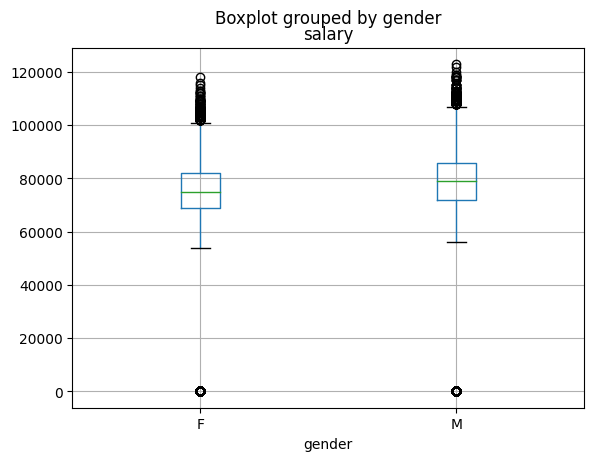

In [15]:
df.boxplot(column="salary", by="gender")

<Axes: title={'center': 'salary'}, xlabel='company'>

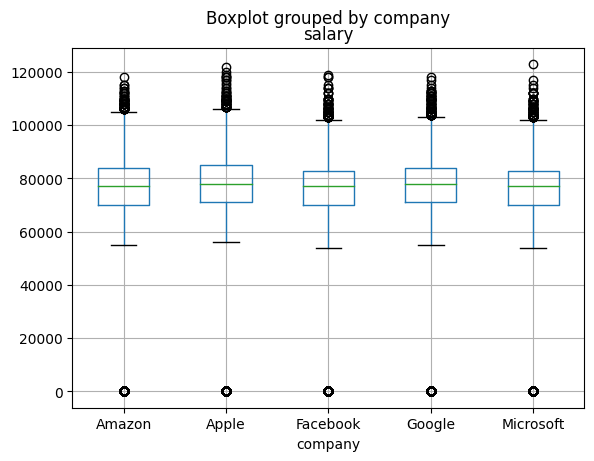

In [16]:
df.boxplot(column="salary", by="company")

<Axes: title={'center': 'salary'}, xlabel='position_level'>

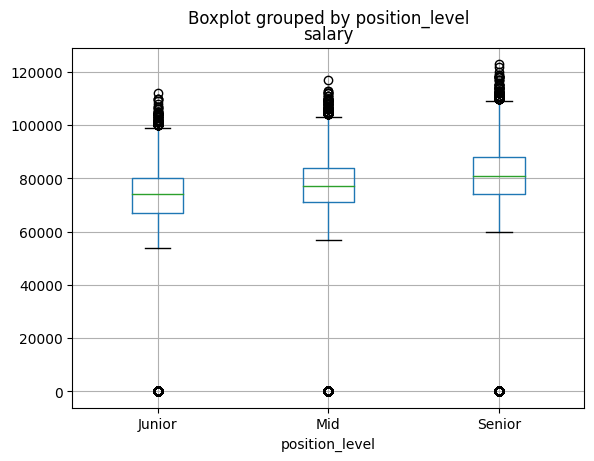

In [17]:
df.boxplot(column="salary", by="position_level")

In [23]:
df["promoted"] = ~df["last_promotion_date"].isna()

<Axes: title={'center': 'salary'}, xlabel='promoted'>

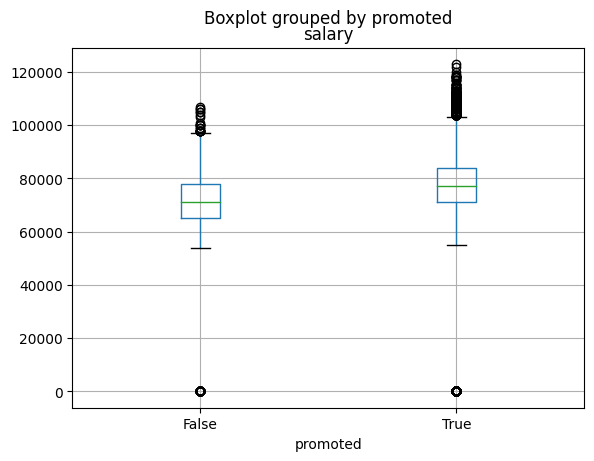

In [24]:
df.boxplot(column="salary", by="promoted")

In [26]:
company_replace = {"Apple": 4, "Google": 3, "Amazon": 2, "Facebook": 1, "Microsoft": 0}
position_replace = {"Senior": 2, "Mid": 1, "Junior": 0}
gender_replace = {"M": 1, "F": 0}

df = df.replace(company_replace)
df = df.replace(position_replace)
df = df.replace(gender_replace)

In [38]:
df.head()

X = df[["company", "gender", "position_level", "performance_score", "work_hours_per_week", "experience_years", "has_certifications", "promoted"]]
y = df["salary"]

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

mae = np.mean(np.abs(y_test - y_pred))
mse = np.mean((y_test - y_pred)**2)
rmse = np.sqrt(np.mean((y_test - y_pred)**2))
r2 = r2_score(y_test, y_pred)
print(f"MAE Score: {mae}\nMSE Score: {mse}\nRMSE Score: {rmse}\nR^2 Score: {r2}")

MAE Score: 7524.169631808584
MSE Score: 293054194.3072179
RMSE Score: 17118.825728046242
R^2 Score: 0.18016190506635033


In [41]:
joblib.dump(model, "model.pkl")

['model.pkl']